# kapsama ve 2020 bosluklari

amac model etiketindeki 0 larin ne anlama geldigini anlamak
kayit yok = gercekten bos mu yoksa nokta o sirada hizmette degil / veri eksik mi
bunu netlestirmeden egitim ve eda yanlis yorumlanabilir

bu notebook kesin kurulum tarihi bulmaz sadece gozlenen kayitlardan kanit cikarir
karari egeyle birlikte verecegiz

## 1 oturumlari yukle

In [ ]:
from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_dir = project_dir / "data" / "raw" / "acn"
json_files = sorted(data_dir.glob("caltech_*.json"))
assert len(json_files) == 14

all_sessions = []
for file_path in json_files:
    with file_path.open(encoding="utf-8") as file:
        items = json.load(file)["_items"]
    for session in items:
        session = dict(session)
        session["_source_file"] = file_path.name
        all_sessions.append(session)

sessions = pd.DataFrame(all_sessions)
for column in ["connectionTime", "disconnectTime"]:
    sessions[f"{column}_utc"] = pd.to_datetime(
        sessions[column], utc=True, errors="coerce"
    )

sessions = sessions.sort_values("connectionTime_utc").reset_index(drop=True)
sessions["month_utc"] = sessions["connectionTime_utc"].dt.strftime("%Y-%m")
sessions["month_local"] = (
    sessions["connectionTime_utc"]
    .dt.tz_convert("America/Los_Angeles")
    .dt.strftime("%Y-%m")
)

print("oturum", len(sessions), "nokta", sessions["stationID"].nunique())
print("ilk", sessions["connectionTime_utc"].min())
print("son", sessions["connectionTime_utc"].max())

Matplotlib is building the font cache; this may take a moment.


oturum 31424 nokta 55
ilk 2018-04-25 11:08:04+00:00
son 2021-09-14 01:52:37+00:00


## 2 nokta bazinda ilk son kayit

her stationID icin gozlenen ilk ve son baglanti
bu tarihleri gercek acilis kapanis sanmiyoruz sadece veride gorunen aralik

In [2]:
station_coverage = (
    sessions.groupby("stationID")["connectionTime_utc"]
    .agg(first_connection="min", last_connection="max", session_count="count")
    .reset_index()
)
station_coverage["span_days"] = (
    station_coverage["last_connection"] - station_coverage["first_connection"]
).dt.days
station_coverage = station_coverage.sort_values("session_count")

print("en az oturumlu 10 nokta")
display(station_coverage.head(10))
print("en cok oturumlu 10 nokta")
display(station_coverage.tail(10).sort_values("session_count", ascending=False))

en az oturumlu 10 nokta


,stationID,first_connection,last_connection,session_count,span_days
40,2-39-82-385,2018-09-03 18:05:27+00:00,2021-05-19 18:47:01+00:00,8,989
39,2-39-82-384,2018-07-18 23:54:48+00:00,2021-03-01 01:23:55+00:00,15,956
5,2-39-125-559,2018-04-26 03:33:58+00:00,2021-03-18 08:43:34+00:00,75,1057
42,2-39-83-387,2018-06-03 07:37:26+00:00,2021-04-07 20:06:54+00:00,76,1039
13,2-39-129-563,2018-05-03 17:11:34+00:00,2020-02-05 21:08:05+00:00,88,643
9,2-39-127-561,2018-05-01 20:07:55+00:00,2021-05-11 16:57:56+00:00,90,1105
17,2-39-131-565,2018-05-03 21:34:37+00:00,2019-12-03 17:19:33+00:00,104,578
21,2-39-139-567,2018-05-01 19:33:50+00:00,2021-07-20 03:47:35+00:00,108,1175
11,2-39-128-562,2018-05-05 00:48:43+00:00,2020-02-26 16:52:37+00:00,120,662
7,2-39-126-560,2018-05-09 19:03:37+00:00,2020-04-24 04:07:49+00:00,124,715


en cok oturumlu 10 nokta


,stationID,first_connection,last_connection,session_count,span_days
20,2-39-139-28,2018-04-25 14:43:50+00:00,2021-09-13 14:27:47+00:00,1808,1236
16,2-39-131-30,2018-04-26 20:27:49+00:00,2021-09-13 14:52:18+00:00,1412,1235
12,2-39-129-17,2018-05-01 01:14:27+00:00,2021-09-13 18:08:24+00:00,1141,1231
38,2-39-81-4550,2020-11-18 23:36:26+00:00,2021-09-14 01:52:37+00:00,1130,299
45,2-39-89-25,2018-04-25 15:48:23+00:00,2021-09-13 21:12:53+00:00,1095,1237
4,2-39-125-21,2018-04-25 15:30:31+00:00,2021-09-13 15:53:01+00:00,1056,1237
8,2-39-127-19,2018-04-25 15:33:45+00:00,2021-09-13 15:21:14+00:00,1035,1236
18,2-39-138-29,2018-04-26 01:49:57+00:00,2021-09-13 18:34:00+00:00,1007,1236
33,2-39-79-379,2018-04-25 14:37:06+00:00,2021-09-13 15:21:12+00:00,940,1237
0,2-39-123-23,2018-04-25 16:01:26+00:00,2021-09-13 21:17:04+00:00,918,1237


## 3 nokta icinde uzun bosluklar

ardisik iki baglanti arasindaki en uzun sure
cok uzun bosluk noktanin o donemde az kullanildigini veya kayit/hizmet kesintisi olabilecegini gosterir

In [3]:
gap_rows = []
for station_id, group in sessions.groupby("stationID"):
    times = group["connectionTime_utc"].sort_values()
    gaps = times.diff().dropna()
    if gaps.empty:
        continue
    max_gap = gaps.max()
    gap_rows.append(
        {
            "stationID": station_id,
            "session_count": len(group),
            "max_gap_days": max_gap.days,
            "max_gap": max_gap,
            "median_gap_hours": gaps.median() / pd.Timedelta(hours=1),
        }
    )

station_gaps = pd.DataFrame(gap_rows).sort_values("max_gap_days", ascending=False)
print("en uzun bosluklu 15 nokta")
display(station_gaps.head(15))
print("30 gunden uzun max boslugu olan nokta", (station_gaps["max_gap_days"] > 30).sum())
print("180 gunden uzun max boslugu olan nokta", (station_gaps["max_gap_days"] > 180).sum())

en uzun bosluklu 15 nokta


,stationID,session_count,max_gap_days,max_gap,median_gap_hours
40,2-39-82-385,8,731,731 days 21:56:11,384.692500
21,2-39-139-567,108,621,621 days 12:19:17,27.083333
52,2-39-92-442,509,545,545 days 05:09:57,23.852083
9,2-39-127-561,90,523,523 days 20:47:39,48.168611
25,2-39-78-363,620,493,493 days 21:30:03,21.256944
54,2-39-95-444,400,490,490 days 23:40:18,24.434722
5,2-39-125-559,75,490,490 days 15:52:54,50.024722
19,2-39-138-566,177,455,455 days 22:49:06,23.970972
47,2-39-90-26,573,415,415 days 23:51:53,23.294444
24,2-39-78-362,459,396,396 days 22:06:11,23.876528


30 gunden uzun max boslugu olan nokta 53
180 gunden uzun max boslugu olan nokta 29


## 4 aylik oturum sayisi ozellikle 2020

2020 eylul ve ekimde genel oturum 0
bunu kullanim dususu mu kayit eksigi mi diye ayirmak icin once sayilari net yaziyoruz

In [4]:
monthly = (
    sessions.groupby("month_local")
    .agg(
        session_count=("sessionID", "count"),
        active_stations=("stationID", "nunique"),
    )
    .sort_index()
)

# 2018-04 ile 2021-09 arasi tum aylari goster eksik ay 0 olsun
all_months = pd.period_range("2018-04", "2021-09", freq="M").astype(str)
monthly = monthly.reindex(all_months, fill_value=0)
monthly.index.name = "month_local"

print("2020 aylari")
display(monthly.loc[[m for m in monthly.index if m.startswith("2020")]])

zero_months = monthly[monthly["session_count"] == 0]
print("oturum 0 olan aylar")
display(zero_months)

2020 aylari


,session_count,active_stations
month_local,,
2020-01,822,44
2020-02,847,46
2020-03,381,44
2020-04,24,16
2020-05,17,10
2020-06,40,19
2020-07,66,19
2020-08,5,5
2020-09,0,0


oturum 0 olan aylar


,session_count,active_stations
month_local,,
2020-09,0,0
2020-10,0,0


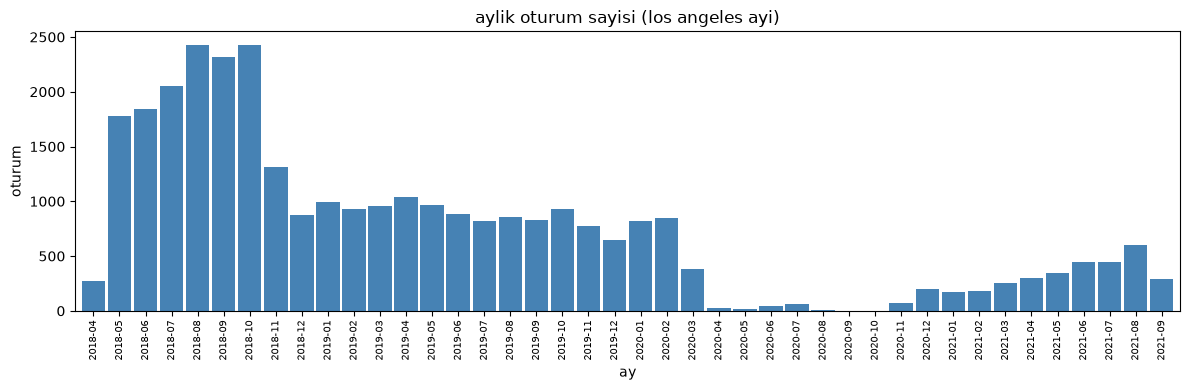

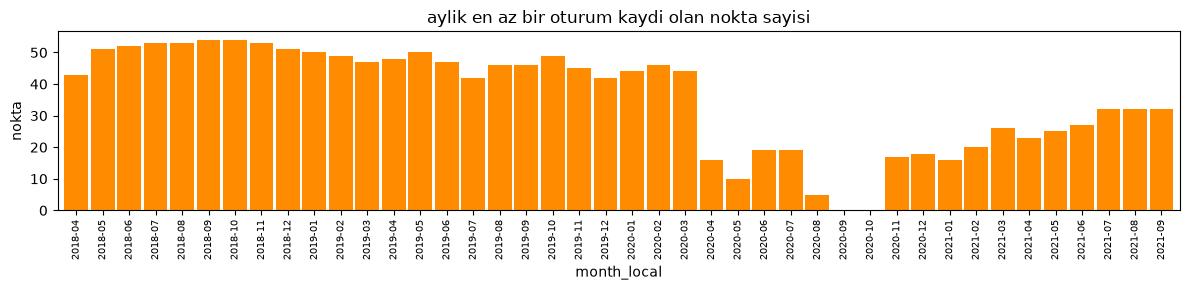

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
monthly["session_count"].plot(ax=ax, kind="bar", width=0.9, color="steelblue")
ax.set_title("aylik oturum sayisi (los angeles ayi)")
ax.set_ylabel("oturum")
ax.set_xlabel("ay")
ax.tick_params(axis="x", labelrotation=90, labelsize=7)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 3))
monthly["active_stations"].plot(ax=ax, kind="bar", width=0.9, color="darkorange")
ax.set_title("aylik en az bir oturum kaydi olan nokta sayisi")
ax.set_ylabel("nokta")
ax.tick_params(axis="x", labelrotation=90, labelsize=7)
plt.tight_layout()
plt.show()

## 5 2020 eylul ekim cevresi

sifir aylarin hemen oncesi ve sonrasi
ani kesilip ani donus kayit kesintisine daha cok benzer
yavas dusus kullanim azalmasina daha cok benzer
yine de tek basina kanit degil

In [6]:
window = ["2020-06", "2020-07", "2020-08", "2020-09", "2020-10", "2020-11", "2020-12", "2021-01"]
display(monthly.loc[window])

# sifir aylarda hic baglanti yok mu disconnect de yok mu
sep_oct = sessions["month_local"].isin(["2020-09", "2020-10"])
print("2020-09/10 baglanti oturumu", int(sep_oct.sum()))

disconnect_local = sessions["disconnectTime_utc"].dt.tz_convert("America/Los_Angeles")
disc_months = disconnect_local.dt.strftime("%Y-%m")
print(
    "2020-09/10 icinde biten oturum",
    int(disc_months.isin(["2020-09", "2020-10"]).sum()),
)

# agustos son baglanti ne zaman kasim ilk baglanti ne zaman
before = sessions[sessions["month_local"] == "2020-08"]["connectionTime_utc"]
after = sessions[sessions["month_local"] == "2020-11"]["connectionTime_utc"]
print("2020-08 son baglanti", before.max() if len(before) else None)
print("2020-11 ilk baglanti", after.min() if len(after) else None)
if len(before) and len(after):
    print("aradaki bosluk", after.min() - before.max())

,session_count,active_stations
month_local,,
2020-06,40,19
2020-07,66,19
2020-08,5,5
2020-09,0,0
2020-10,0,0
2020-11,72,17
2020-12,201,18
2021-01,174,16


2020-09/10 baglanti oturumu 0
2020-09/10 icinde biten oturum 0
2020-08 son baglanti 2020-08-03 22:02:13+00:00
2020-11 ilk baglanti 2020-11-18 21:37:02+00:00
aradaki bosluk 106 days 23:34:49


## 6 egeye karar notu

su anki modelde kayit olmayan saatler 0
asagidaki bulgulara gore 0 i nasil yorumlayacagimizi konusmamiz lazim

In [7]:
summary = {
    "nokta_sayisi": int(sessions["stationID"].nunique()),
    "oturum_0_aylar": list(zero_months.index),
    "2020_09_oturum": int(monthly.loc["2020-09", "session_count"]),
    "2020_10_oturum": int(monthly.loc["2020-10", "session_count"]),
    "30gunden_uzun_bosluklu_nokta": int((station_gaps["max_gap_days"] > 30).sum()),
    "180gunden_uzun_bosluklu_nokta": int((station_gaps["max_gap_days"] > 180).sum()),
    "en_uzun_bosluk_gun": int(station_gaps["max_gap_days"].max()),
    "en_uzun_bosluk_nokta": station_gaps.iloc[0]["stationID"],
}
for key, value in summary.items():
    print(f"{key}: {value}")

print()
print("karar secenekleri")
print("A kayit yok = 0 bos kalsin basit ama hizmet disi saatleri bos sayar")
print("B noktanin ilk-son kayit araligi disini modelden cikar / maskele")
print("C uzun bosluklari ayri bayrakla ama etiketi 0 birak")
print("bu notebook A B C secmez sadece kanit uretir")

nokta_sayisi: 55
oturum_0_aylar: ['2020-09', '2020-10']
2020_09_oturum: 0
2020_10_oturum: 0
30gunden_uzun_bosluklu_nokta: 53
180gunden_uzun_bosluklu_nokta: 29
en_uzun_bosluk_gun: 731
en_uzun_bosluk_nokta: 2-39-82-385

karar secenekleri
A kayit yok = 0 bos kalsin basit ama hizmet disi saatleri bos sayar
B noktanin ilk-son kayit araligi disini modelden cikar / maskele
C uzun bosluklari ayri bayrakla ama etiketi 0 birak
bu notebook A B C secmez sadece kanit uretir


## sonuc

nokta kapsami ve 2020 sifir aylari cikarildi
sonraki adim egeyle 0 etiketi yorumunu netlestirmek
sonra takvim ve open-meteo